# 7. Error analysis
Three parts, as in Section 4.6: (1) confusion matrices of the four models and upward against downward days, (2) where the models fail: ROC-AUC per held-out stock, sector and test year, averaged over the four models, (3) permutation feature importance with its spread across folds (LightGBM). Figures are saved in `figures/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score, matthews_corrcoef, accuracy_score

results = pd.concat([pd.read_csv(f) for f in sorted(Path("results").glob("results_*.csv"))], ignore_index=True)
predictions = pd.concat([pd.read_csv(f, parse_dates=["Date"])
                         for f in sorted(Path("results").glob("predictions_*.csv.gz"))], ignore_index=True)

MODELS = [m for m in ["lr", "lgbm", "cat", "tabpfn"] if m in set(results["model"])]
SETTINGS = ["within", "cross_stock", "cross_sector"]
NAMES = {"lr": "Logistic Regression", "lgbm": "LightGBM", "cat": "CatBoost", "tabpfn": "TabPFN",
         "within": "Within-stock", "cross_stock": "Cross-stock", "cross_sector": "Cross-sector"}
print(results.groupby("model").size())

from sklearn.metrics import ConfusionMatrixDisplay

importance = pd.concat([pd.read_csv(f) for f in sorted(Path("results").glob("importance_*.csv"))], ignore_index=True)
COLORS = {"lr": "#4472C4", "lgbm": "#ED7D31", "cat": "#7030A0", "tabpfn": "#7F7F7F"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

### one score per evaluation: metrics of the averaged predictions of the five seeds (as in Gu et al., 2020) ###

def metrics(y, proba):
    pred = (proba >= 0.5).astype(int)
    return {"auc": roc_auc_score(y, proba) if len(np.unique(proba)) > 1 else 0.5,
            "mcc": matthews_corrcoef(y, pred),
            "acc": accuracy_score(y, pred),
            "up_rate": pred.mean(),
            "recall_up": pred[y == 1].mean(),
            "recall_down": 1 - pred[y == 0].mean()}

KEYS = ["setting", "held_out", "test_year", "features", "model"]
per_eval = pd.DataFrame([{**dict(zip(KEYS, key)), **metrics(rows["Target"].to_numpy(), rows["proba"].to_numpy())}
                         for key, rows in predictions.groupby(KEYS)])
pred = predictions[predictions["model"].isin(MODELS)].copy()
pred["pred"] = (pred["proba"] >= 0.5).astype(int)

model
cat         450
lgbm        450
lr           90
majority     45
tabpfn       90
dtype: int64


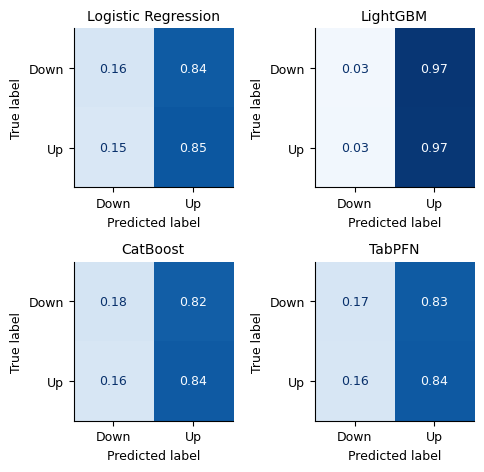

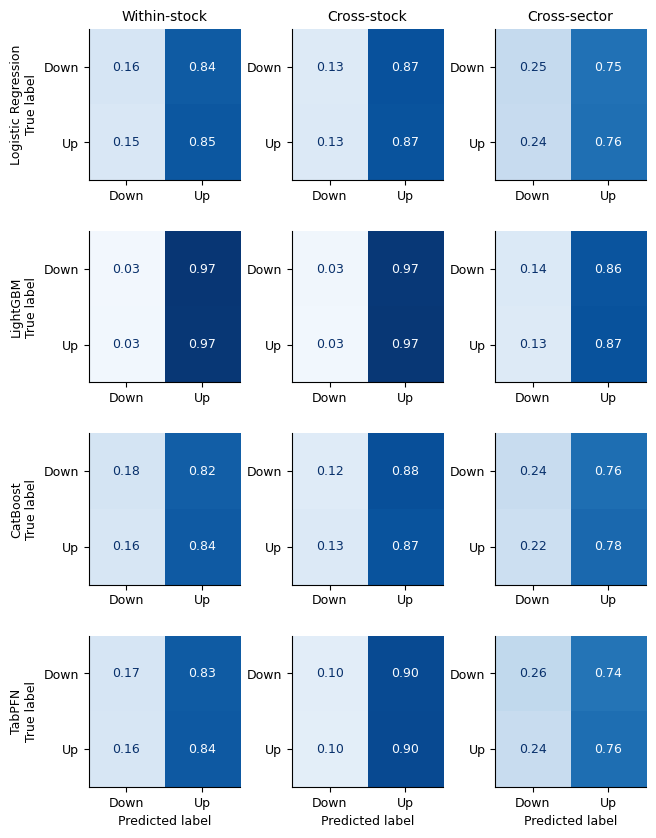

In [2]:
### 1. confusion matrices (all four models, set A), normalised by the true labels as in the Lecture 4 notebook ###
# main text: within-stock setting, one panel per model (2 x 2); same colour scale (0 to 1) in every panel

fig, axes = plt.subplots(2, 2, figsize=(5.0, 4.8))
for ax, m in zip(axes.ravel(), MODELS):
    rows = pred[(pred["setting"] == "within") & (pred["model"] == m) & (pred["features"] == "A")]
    ConfusionMatrixDisplay.from_predictions(rows["Target"], rows["pred"], normalize="true",
                                            display_labels=["Down", "Up"], cmap="Blues",
                                            values_format=".2f", colorbar=False, ax=ax,
                                            im_kw={"vmin": 0, "vmax": 1})
    ax.set_title(NAMES[m], fontsize=10)
fig.tight_layout()
fig.savefig("figures/confusion_within.png", dpi=300)
plt.show()

# appendix: all settings, rows = models, columns = settings

fig, axes = plt.subplots(len(MODELS), 3, figsize=(6.6, 8.6))
for i, m in enumerate(MODELS):
    for j, setting in enumerate(SETTINGS):
        ax = axes[i, j]
        rows = pred[(pred["setting"] == setting) & (pred["model"] == m) & (pred["features"] == "A")]
        ConfusionMatrixDisplay.from_predictions(rows["Target"], rows["pred"], normalize="true",
                                                display_labels=["Down", "Up"], cmap="Blues",
                                                values_format=".2f", colorbar=False, ax=ax,
                                                im_kw={"vmin": 0, "vmax": 1})
        ax.set_title(NAMES[setting] if i == 0 else "", fontsize=10)
        ax.set_xlabel("Predicted label" if i == len(MODELS) - 1 else "")
        ax.set_ylabel(f"{NAMES[m]}\nTrue label" if j == 0 else "")
fig.tight_layout()
fig.savefig("figures/confusion_matrices.png", dpi=300)
plt.show()

In [3]:
### upward against downward days ###

(per_eval[per_eval["model"].isin(MODELS) & (per_eval["features"] == "A")]
 .groupby(["setting", "model"])[["up_rate", "recall_up", "recall_down"]].mean()
 .rename(columns={"up_rate": "predicted up", "recall_up": "up days correct", "recall_down": "down days correct"})
 .reindex(pd.MultiIndex.from_product([SETTINGS, MODELS], names=["setting", "model"])).round(3))

predicted up  up days correct  down days correct
setting      model                                                   
within       lr             0.842            0.848              0.164
             lgbm           0.972            0.971              0.026
             cat            0.830            0.837              0.179
             tabpfn         0.838            0.842              0.166
cross_stock  lr             0.869            0.866              0.128
             lgbm           0.969            0.970              0.034
             cat            0.873            0.867              0.121
             tabpfn         0.900            0.900              0.102
cross_sector lr             0.753            0.755              0.250
             lgbm           0.866            0.874              0.144
             cat            0.773            0.782              0.238
             tabpfn         0.748            0.759              0.264

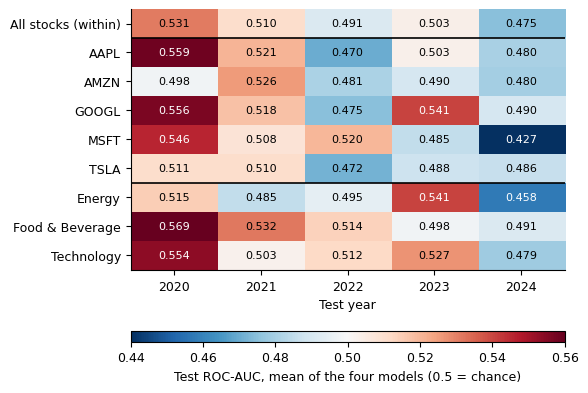

Mean per test year: {2020: 0.538, 2021: 0.512, 2022: 0.492, 2023: 0.508, 2024: 0.474}


test_year,2020,2021,2022,2023,2024
held_out,,,,,
All stocks (within),0.531,0.510,0.491,0.503,0.475
AAPL,0.559,0.521,0.470,0.503,0.480
AMZN,0.498,0.526,0.481,0.490,0.480
GOOGL,0.556,0.518,0.475,0.541,0.490
MSFT,0.546,0.508,0.520,0.485,0.427
TSLA,0.511,0.510,0.472,0.488,0.486
Energy,0.515,0.485,0.495,0.541,0.458
Food & Beverage,0.569,0.532,0.514,0.498,0.491
Technology,0.554,0.503,0.512,0.527,0.479


In [4]:
### 2. where the models fail: ROC-AUC per held-out stock or sector and test year (set A) ###
# each cell is the mean ROC-AUC of the four models; RQ1 found no difference between them

mean_auc = (per_eval[per_eval["model"].isin(MODELS) & (per_eval["features"] == "A")]
            .groupby(["setting", "held_out", "test_year"])["auc"].mean().reset_index())
heat = pd.concat([mean_auc[mean_auc["setting"] == s].pivot(index="held_out", columns="test_year", values="auc")
                  for s in SETTINGS]).rename(index={"all": "All stocks (within)"})

fig, ax = plt.subplots(figsize=(5.6, 4.4))
image = ax.imshow(heat.values, cmap="RdBu_r", vmin=0.44, vmax=0.56, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.values[i, j]
        ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value - 0.5) > 0.04 else "black")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.axhline(0.5, color="black", lw=1.2)     # within | cross-stock
ax.axhline(5.5, color="black", lw=1.2)     # cross-stock | cross-sector
ax.set_xlabel("Test year")
bar = fig.colorbar(image, ax=ax, orientation="horizontal", fraction=0.05, pad=0.18, aspect=40)
bar.set_label("Test ROC-AUC, mean of the four models (0.5 = chance)")
fig.savefig("figures/heatmap_auc.png", dpi=300, bbox_inches="tight")
plt.show()

print("Mean per test year:", heat.mean().round(3).to_dict())
heat.round(3)

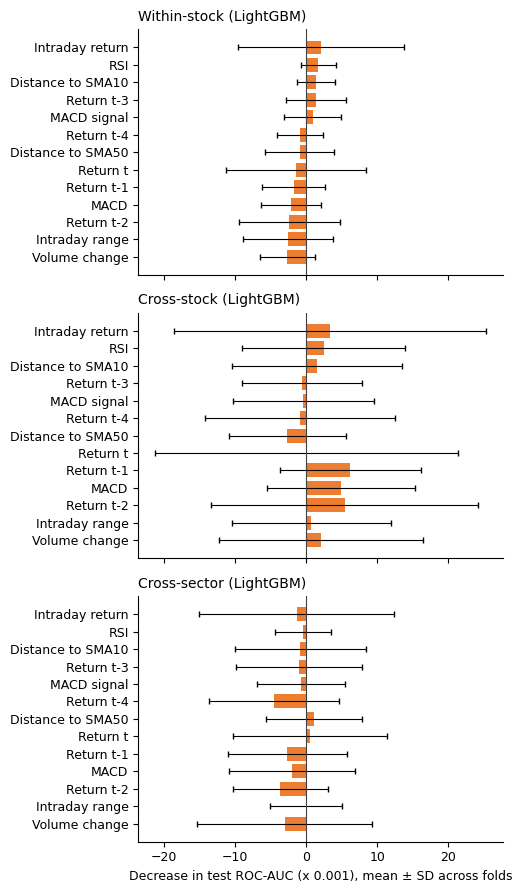

mean     std
setting      feature                        
cross_sector dist_sma10      -0.0008  0.0092
             dist_sma50       0.0011  0.0068
             dlog_volume     -0.0030  0.0123
             hl_range         0.0000  0.0050
             intraday_ret    -0.0013  0.0137
             macd_rel        -0.0020  0.0089
             macd_signal_rel -0.0007  0.0062
             ret_lag1         0.0005  0.0108
             ret_lag2        -0.0026  0.0083
             ret_lag3        -0.0036  0.0067
             ret_lag4        -0.0010  0.0088
             ret_lag5        -0.0045  0.0092
             rsi14           -0.0004  0.0039
cross_stock  dist_sma10       0.0015  0.0119
             dist_sma50      -0.0026  0.0082
             dlog_volume      0.0021  0.0143
             hl_range         0.0008  0.0111
             intraday_ret     0.0034  0.0219
             macd_rel         0.0049  0.0104
             macd_signal_rel -0.0004  0.0099
             ret_lag1         0.0001  0.0213
             ret_lag2         0.0062  0.0099
             ret_lag3         0.0054  0.0188
             ret_lag4        -0.0005  0.0084
             ret_lag5        -0.0008  0.0134
             rsi14            0.0025  0.0115
within       dist_sma10       0.0014  0.0026
             dist_sma50      -0.0009  0.0048
             dlog_volume     -0.0027  0.0039
             hl_range        -0.0026  0.0063
             intraday_ret     0.0021  0.0116
             macd_rel        -0.0021  0.0042
             macd_signal_rel  0.0009  0.0040
             ret_lag1        -0.0014  0.0098
             ret_lag2        -0.0017  0.0044
             ret_lag3        -0.0024  0.0071
             ret_lag4         0.0014  0.0042
             ret_lag5        -0.0009  0.0033
             rsi14            0.0017  0.0025

In [5]:
### 3. permutation importance (LightGBM, set B): mean and SD across folds, with error bars as in Lecture 3 ###

LABELS = {"ret_lag1": "Return t", "ret_lag2": "Return t-1", "ret_lag3": "Return t-2",
          "ret_lag4": "Return t-3", "ret_lag5": "Return t-4", "hl_range": "Intraday range",
          "intraday_ret": "Intraday return", "dlog_volume": "Volume change",
          "dist_sma10": "Distance to SMA10", "dist_sma50": "Distance to SMA50",
          "rsi14": "RSI", "macd_rel": "MACD", "macd_signal_rel": "MACD signal"}

imp = (importance[(importance["model"] == "lgbm") & (importance["features"] == "B")]
       .groupby(["setting", "feature"])["importance"].agg(["mean", "std"]))
order = imp.loc["within"].sort_values("mean").index

fig, axes = plt.subplots(3, 1, figsize=(5.2, 9), sharex=True)
for ax, setting in zip(axes, SETTINGS):
    rows = imp.loc[setting].reindex(order)
    ax.barh([LABELS[f] for f in order], rows["mean"] * 1000, xerr=rows["std"] * 1000,
            color=COLORS["lgbm"], error_kw={"elinewidth": 0.8, "capsize": 2})
    ax.axvline(0, color="#404040", lw=0.8)
    ax.set_title(f"{NAMES[setting]} (LightGBM)", fontsize=10, loc="left")
axes[-1].set_xlabel("Decrease in test ROC-AUC (x 0.001), mean ± SD across folds")
fig.tight_layout()
fig.savefig("figures/importance_lgbm.png", dpi=300)
plt.show()

imp.round(4)